#Week3

##Dataset

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Create a folder for Week 3

In [7]:
import os

BASE_DIR = "/content/drive/MyDrive/Week3_Object_Detection"

os.makedirs(BASE_DIR, exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


In [3]:
!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key="dmgJjDY6sKiNl27cu60d")
project = rf.workspace("grape-ldrtx").project("fruit-and-vegetable-s8arz")
version = project.version(9)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 39.1 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fruit-and-vegetable-9 in yolov8:: 100%|██████████| 6252/6252 [00:01<00:00, 3969.74it/s]


verfiy the dataset

In [5]:
dataset = version.download("yolov8", location="/content/drive/MyDrive/Week3_Object_Detection/dataset")
print("Dataset location:", dataset.location)
print("Dataset files:")
!ls /content/drive/MyDrive/Week3_Object_Detection/dataset


Extracting Dataset Version Zip to /content/drive/MyDrive/Week3_Object_Detection/dataset in yolov8:: 100%|██████████| 6252/6252 [01:41<00:00, 61.57it/s]


Dataset location: /content/drive/MyDrive/Week3_Object_Detection/dataset
Dataset files:
data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [9]:
import yaml
yaml_path = os.path.join(dataset.location, "data.yaml")

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("Classes:", data_config["names"])
print("Number of classes:", data_config["nc"])

Classes: ['apple', 'cucumber', 'orange', 'pepper', 'tomato']
Number of classes: 5


##Implement IoU (Intersection over Union) from Scratch

In [10]:

def calculate_iou(box1, box2):

    # 1. Calculate intersection coordinates
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    # 2. Calculate intersection area
    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)

    intersection_area = intersection_width * intersection_height

    # 3. Calculate area of each box
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    # 4. Calculate union area
    union_area = area1 + area2 - intersection_area

    # 5. Calculate IoU
    if union_area == 0:
        return 0.0

    iou = intersection_area / union_area

    return iou


In [11]:

box1 = [100, 100, 300, 300]
box2 = [200, 200, 400, 400]

iou = calculate_iou(box1, box2)

print("IoU:", iou)


IoU: 0.14285714285714285


In [12]:
#Verify against TorchVision
#compare our implementation with the official library implementation

import torch
from torchvision.ops import box_iou

box1 = torch.tensor([[100, 100, 300, 300]], dtype=torch.float32)
box2 = torch.tensor([[200, 200, 400, 400]], dtype=torch.float32)

library_iou = box_iou(box1, box2)

print("Our IoU:", calculate_iou(
    box1[0].tolist(),
    box2[0].tolist()
))

print("TorchVision IoU:", library_iou.item())


Our IoU: 0.14285714285714285
TorchVision IoU: 0.1428571492433548


In [13]:
#Test different scenarios
# Test 1: Identical boxes
print("Identical:", calculate_iou(
    [0, 0, 100, 100],
    [0, 0, 100, 100]
))

# Test 2: No overlap
print("No overlap:", calculate_iou(
    [0, 0, 100, 100],
    [200, 200, 300, 300]
))

# Test 3: Partial overlap
print("Partial overlap:", calculate_iou(
    [0, 0, 100, 100],
    [50, 50, 150, 150]
))

Identical: 1.0
No overlap: 0.0
Partial overlap: 0.14285714285714285


##Implement Non-Maximum Suppression (NMS)

In [14]:

def nms(boxes, scores, iou_threshold):

    # 1. Sort boxes by confidence scores (highest first)
    sorted_indices = sorted(
        range(len(scores)),
        key=lambda i: scores[i],
        reverse=True
    )

    selected_boxes = []

    # 2. Repeat until no boxes remain
    while sorted_indices:

        # 3. Select box with highest confidence
        best_index = sorted_indices.pop(0)

        # Keep this box
        selected_boxes.append(best_index)

        remaining_boxes = []

        # 4. Compare selected box with remaining boxes
        for index in sorted_indices:

            iou = calculate_iou(
                boxes[best_index],
                boxes[index]
            )

            # 5. Keep boxes whose IoU is below threshold
            if iou <= iou_threshold:
                remaining_boxes.append(index)

        sorted_indices = remaining_boxes

    return selected_boxes

In [15]:
#Test NMS implementation
boxes = [
    [100, 100, 300, 300],  # Box A
    [120, 120, 280, 280],  # Box B
    [350, 350, 450, 450]   # Box C
]

scores = [0.9, 0.8, 0.7]

iou_threshold = 0.5

selected = nms(boxes, scores, iou_threshold)

print("Selected box indices:", selected)


Selected box indices: [0, 2]


In [16]:
#compare implementation with the official NMS implementation
import torch
from torchvision.ops import nms as torchvision_nms

# Convert boxes and scores into tensors
boxes_tensor = torch.tensor(boxes, dtype=torch.float32)
scores_tensor = torch.tensor(scores, dtype=torch.float32)

# Our implementation
our_results = nms(boxes, scores, 0.5)

# TorchVision implementation
library_results = torchvision_nms(
    boxes_tensor,
    scores_tensor,
    0.5
)

print("Our NMS:", our_results)
print("TorchVision NMS:", library_results.tolist())

print("Results match:", our_results == library_results.tolist())


Our NMS: [0, 2]
TorchVision NMS: [0, 2]
Results match: True


In [17]:
#Test different IoU thresholds
print("Threshold 0.3:", nms(boxes, scores, 0.3))
print("Threshold 0.5:", nms(boxes, scores, 0.5))
print("Threshold 0.8:", nms(boxes, scores, 0.8))

Threshold 0.3: [0, 2]
Threshold 0.5: [0, 2]
Threshold 0.8: [0, 1, 2]


##Fine-tune a pretrained detector


In [25]:
!pip install ultralytics -q
import os
import torch
import yaml
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("Libraries imported successfully!")

Libraries imported successfully!


In [26]:
#Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
BASE_DIR = "/content/drive/MyDrive/Week3_Object_Detection"
DATASET_DIR = os.path.join(BASE_DIR, "dataset")
YAML_PATH = os.path.join(DATASET_DIR, "data.yaml")
print("Dataset exists:", os.path.exists(YAML_PATH))
print("Dataset YAML:", YAML_PATH)

Dataset exists: True
Dataset YAML: /content/drive/MyDrive/Week3_Object_Detection/dataset/data.yaml


In [29]:
with open(YAML_PATH, "r") as file:
    data_config = yaml.safe_load(file)

print("Number of classes:", data_config["nc"])
print("Class names:", data_config["names"])

Number of classes: 5
Class names: ['apple', 'cucumber', 'orange', 'pepper', 'tomato']


In [30]:
#load pre-trainedmodel
model = YOLO("yolov8n.pt")
print("Pretrained YOLOv8n loaded successfully!")

Pretrained YOLOv8n loaded successfully!


In [31]:
#train
results = model.train(
    data=YAML_PATH,
    epochs=10,
    imgsz=416,
    batch=4,
    device="cpu",
    workers=2,
    project=BASE_DIR,
    name="fruit_vegetable_training",
    exist_ok=True
)

Ultralytics 8.4.210 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Week3_Object_Detection/dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fruit_vegetable_trainin

In [32]:
#Save and load the best model
BEST_MODEL_PATH = os.path.join(
    BASE_DIR,
    "fruit_vegetable_training",
    "weights",
    "best.pt"
)

print("Best model exists:", os.path.exists(BEST_MODEL_PATH))

Best model exists: True


In [33]:
best_model = YOLO(BEST_MODEL_PATH)
print("Best model loaded successfully!")

Best model loaded successfully!


In [34]:
#visualize the prediction
TEST_IMAGES = os.path.join(DATASET_DIR, "test", "images")

predictions = best_model.predict(
    source=TEST_IMAGES,
    conf=0.25,
    device="cpu",
    save=True
)


image 1/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.16fbd14605bd5ca3ad24f9d70973aa93.jpg: 416x416 2 apples, 121.5ms
image 2/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.38373a3af5ca6e5e40f390142a4fe3be.jpg: 416x416 2 apples, 94.4ms
image 3/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.91fd11a9e42d343a8f1ea15759ba1477.jpg: 416x416 1 apple, 1 orange, 92.7ms
image 4/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00006_jpeg_jpg.rf.1d2f875cc387fb950881c6b62f81283c.jpg: 416x416 1 apple, 221.4ms
image 5/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00007_jpeg_jpg.rf.7713194e97caf9eeb04bdb5f84bf2a7a.jpg: 416x416 1 apple, 97.1ms
image 6/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00023_jpeg_jpg.rf.b028075a36db6248cb0dd529c27213a7.jpg: 416x416 1 apple, 92.8ms
image 7/390 /content/drive/MyDr

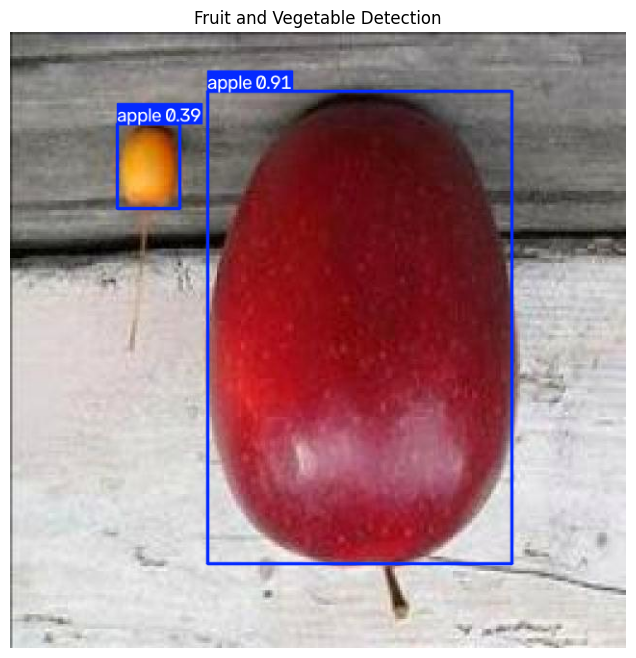

In [35]:
result = predictions[0]

image = result.plot()

plt.figure(figsize=(10, 8))
plt.imshow(image[:, :, ::-1])
plt.axis("off")
plt.title("Fruit and Vegetable Detection")
plt.show()

##Evaluate the model using mAP

In [36]:
#Run validation on the test dataset
metrics = best_model.val(
    data=YAML_PATH,
    split="test",
    imgsz=416,
    batch=4,
    device="cpu",
    workers=2,
    plots=True
)

Ultralytics 8.4.210 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.1 ms, read: 18.4±11.6 MB/s, size: 43.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Week3_Object_Detection/dataset/test/labels... 390 images, 46 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 390/390 158.8it/s 2.5s
val: New cache created: /content/drive/MyDrive/Week3_Object_Detection/dataset/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 66, len(boxes) = 894. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R   

In [38]:
#Extract evaluation metricsmap50 = metrics.box.map50
map50 = metrics.box.map50
map75 = metrics.box.map75
map_all = metrics.box.map

precision = metrics.box.mp
recall = metrics.box.mr

print("Evaluation Results")
print("-------------------------")
print("Precision:", precision)
print("Recall:", recall)
print("mAP@0.5:", map50)
print("mAP@0.75:", map75)
print("mAP@0.5:0.95:", map_all)

Evaluation Results
-------------------------
Precision: 0.8578554779268931
Recall: 0.7918129864904644
mAP@0.5: 0.8469628446305177
mAP@0.75: 0.7306701638162795
mAP@0.5:0.95: 0.6436473156842675


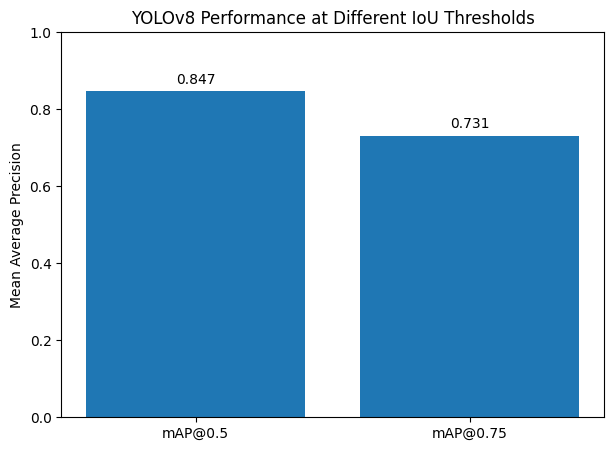

mAP@0.5: 0.8469628446305177
mAP@0.75: 0.7306701638162795


In [53]:
#Compare mAP 0.5 and mAP 0.75
import matplotlib.pyplot as plt

labels = ["mAP@0.5", "mAP@0.75"]
values = [map50, map75]

plt.figure(figsize=(7, 5))

plt.bar(labels, values)

plt.ylim(0, 1)
plt.ylabel("Mean Average Precision")
plt.title("YOLOv8 Performance at Different IoU Thresholds")

for i, value in enumerate(values):
    plt.text(i, value + 0.02, f"{value:.3f}", ha="center")

plt.show()
print("mAP@0.5:", map50)
print("mAP@0.75:", map75)

In [40]:
#Evaluate each class separately
class_names = data_config["names"]

for i, name in enumerate(class_names):
    print(f"{name}:")
    print(f"  Precision: {metrics.box.p[i]:.4f}")
    print(f"  Recall:    {metrics.box.r[i]:.4f}")
    print(f"  AP@0.5:    {metrics.box.ap50[i]:.4f}")
    print(f"  AP@0.5:0.95: {metrics.box.ap[i]:.4f}")

apple:
  Precision: 0.9504
  Recall:    0.8701
  AP@0.5:    0.9190
  AP@0.5:0.95: 0.8213
cucumber:
  Precision: 0.9293
  Recall:    0.7574
  AP@0.5:    0.8043
  AP@0.5:0.95: 0.6009
orange:
  Precision: 0.7216
  Recall:    0.8367
  AP@0.5:    0.8119
  AP@0.5:0.95: 0.6900
pepper:
  Precision: 0.7981
  Recall:    0.9041
  AP@0.5:    0.9273
  AP@0.5:0.95: 0.6343
tomato:
  Precision: 0.8899
  Recall:    0.5907
  AP@0.5:    0.7723
  AP@0.5:0.95: 0.4716


In [41]:
#Analyze False Positives and False Negatives
TEST_IMAGES = os.path.join(DATASET_DIR, "test", "images")
TEST_LABELS = os.path.join(DATASET_DIR, "test", "labels")

predictions = best_model.predict(
    source=TEST_IMAGES,
    conf=0.25,
    iou=0.7,
    imgsz=416,
    device="cpu",
    save=False
)

print("Number of test images:", len(predictions))


image 1/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.16fbd14605bd5ca3ad24f9d70973aa93.jpg: 416x416 2 apples, 113.9ms
image 2/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.38373a3af5ca6e5e40f390142a4fe3be.jpg: 416x416 2 apples, 141.2ms
image 3/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.91fd11a9e42d343a8f1ea15759ba1477.jpg: 416x416 1 apple, 1 orange, 142.6ms
image 4/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00006_jpeg_jpg.rf.1d2f875cc387fb950881c6b62f81283c.jpg: 416x416 1 apple, 358.3ms
image 5/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00007_jpeg_jpg.rf.7713194e97caf9eeb04bdb5f84bf2a7a.jpg: 416x416 1 apple, 345.2ms
image 6/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00023_jpeg_jpg.rf.b028075a36db6248cb0dd529c27213a7.jpg: 416x416 1 apple, 474.8ms
image 7/390 /content/drive/

In [42]:
#Generate predictions on the test images
TEST_IMAGES = os.path.join(DATASET_DIR, "test", "images")
TEST_LABELS = os.path.join(DATASET_DIR, "test", "labels")

predictions = best_model.predict(
    source=TEST_IMAGES,
    conf=0.25,
    iou=0.7,
    imgsz=416,
    device="cpu",
    save=False
)

print("Number of test images:", len(predictions))


image 1/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.16fbd14605bd5ca3ad24f9d70973aa93.jpg: 416x416 2 apples, 104.7ms
image 2/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.38373a3af5ca6e5e40f390142a4fe3be.jpg: 416x416 2 apples, 95.9ms
image 3/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00001_jpeg_jpg.rf.91fd11a9e42d343a8f1ea15759ba1477.jpg: 416x416 1 apple, 1 orange, 96.8ms
image 4/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00006_jpeg_jpg.rf.1d2f875cc387fb950881c6b62f81283c.jpg: 416x416 1 apple, 93.6ms
image 5/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00007_jpeg_jpg.rf.7713194e97caf9eeb04bdb5f84bf2a7a.jpg: 416x416 1 apple, 101.2ms
image 6/390 /content/drive/MyDrive/Week3_Object_Detection/dataset/test/images/-00023_jpeg_jpg.rf.b028075a36db6248cb0dd529c27213a7.jpg: 416x416 1 apple, 91.3ms
image 7/390 /content/drive/MyDr

In [48]:
#Compare predictions with ground-truth labels
import cv2
import numpy as np
from pathlib import Path


def analyze_image(result, label_dir, iou_threshold=0.5):

    image = result.orig_img
    height, width = image.shape[:2]

    # Get predictions
    pred_boxes = result.boxes.xyxy.cpu().numpy()
    pred_classes = result.boxes.cls.cpu().numpy().astype(int)
    pred_scores = result.boxes.conf.cpu().numpy()

    # Find corresponding label file
    label_path = os.path.join(
        label_dir,
        Path(result.path).stem + ".txt"
    )

    gt_boxes = []
    gt_classes = []

    if os.path.exists(label_path):

        with open(label_path, "r") as file:

            for line in file:

                values = list(map(float, line.strip().split()))

                if len(values) < 5:
                    continue

                # Read class ID
                cls = int(values[0])

                # Read first four bounding box coordinates
                cx, cy, w, h = values[1:5]

                # Convert normalized coordinates to xyxy
                x1 = (cx - w / 2) * width
                y1 = (cy - h / 2) * height
                x2 = (cx + w / 2) * width
                y2 = (cy + h / 2) * height

                gt_boxes.append([x1, y1, x2, y2])
                gt_classes.append(cls)

    matched_gt = set()

    true_positives = []
    false_positives = []

    # Sort predictions by confidence
    order = np.argsort(-pred_scores)

    for pred_idx in order:

        best_iou = 0
        best_gt_idx = -1

        for gt_idx, gt_box in enumerate(gt_boxes):

            if gt_idx in matched_gt:
                continue

            if pred_classes[pred_idx] != gt_classes[gt_idx]:
                continue

            iou = calculate_iou(
                pred_boxes[pred_idx].tolist(),
                gt_box
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx

        if best_gt_idx != -1 and best_iou >= iou_threshold:

            true_positives.append(pred_idx)
            matched_gt.add(best_gt_idx)

        else:
            false_positives.append(pred_idx)

    false_negatives = [
        i for i in range(len(gt_boxes))
        if i not in matched_gt
    ]

    return {
        "tp": true_positives,
        "fp": false_positives,
        "fn": false_negatives,
        "pred_boxes": pred_boxes,
        "pred_classes": pred_classes,
        "gt_boxes": gt_boxes,
        "gt_classes": gt_classes,
        "image": image
    }

In [49]:

# Count False Positives and False Negatives

total_tp = 0
total_fp = 0
total_fn = 0

analysis_results = []

for result in predictions:

    analysis = analyze_image(
        result,
        TEST_LABELS,
        iou_threshold=0.5
    )

    total_tp += len(analysis["tp"])
    total_fp += len(analysis["fp"])
    total_fn += len(analysis["fn"])

    analysis_results.append(analysis)

print("Error Analysis")
print("----------------------")
print("True Positives:", total_tp)
print("False Positives:", total_fp)
print("False Negatives:", total_fn)

Error Analysis
----------------------
True Positives: 662
False Positives: 323
False Negatives: 232


In [50]:
#visualize the mistakes
class_names = data_config["names"]

def visualize_errors(analysis):

    image = analysis["image"].copy()

    # Draw True Positive predictions (Green)
    for idx in analysis["tp"]:

        box = analysis["pred_boxes"][idx].astype(int)
        cls = analysis["pred_classes"][idx]

        cv2.rectangle(
            image,
            tuple(box[:2]),
            tuple(box[2:]),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            f"TP: {class_names[cls]}",
            tuple(box[:2]),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

    # Draw False Positive predictions (Red)
    for idx in analysis["fp"]:

        box = analysis["pred_boxes"][idx].astype(int)
        cls = analysis["pred_classes"][idx]

        cv2.rectangle(
            image,
            tuple(box[:2]),
            tuple(box[2:]),
            (0, 0, 255),
            2
        )

        cv2.putText(
            image,
            f"FP: {class_names[cls]}",
            tuple(box[:2]),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 255),
            2
        )

    # Draw False Negative ground-truth boxes (Yellow)
    for idx in analysis["fn"]:

        box = np.array(
            analysis["gt_boxes"][idx]
        ).astype(int)

        cls = analysis["gt_classes"][idx]

        cv2.rectangle(
            image,
            tuple(box[:2]),
            tuple(box[2:]),
            (0, 255, 255),
            2
        )

        cv2.putText(
            image,
            f"FN: {class_names[cls]}",
            tuple(box[:2]),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 255),
            2
        )

    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Detection Error Analysis")
    plt.show()

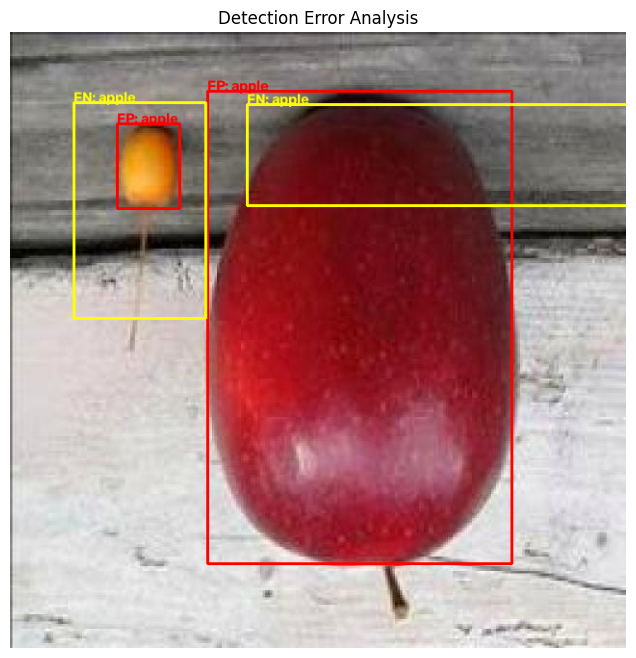

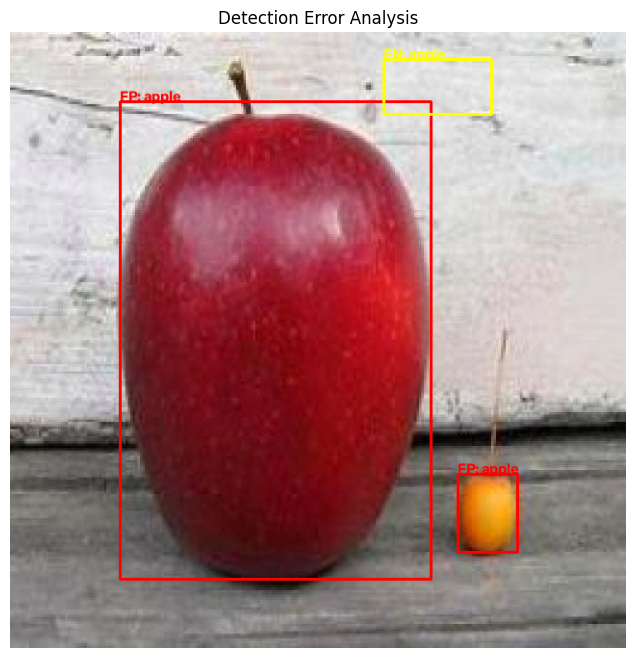

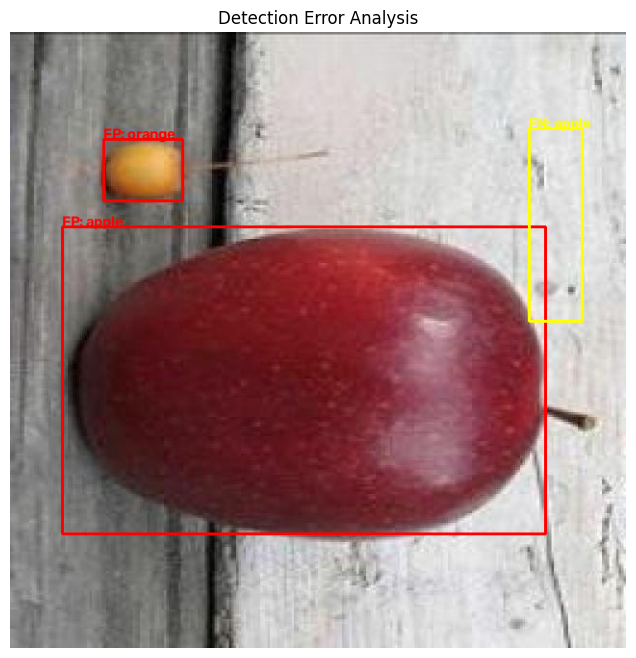

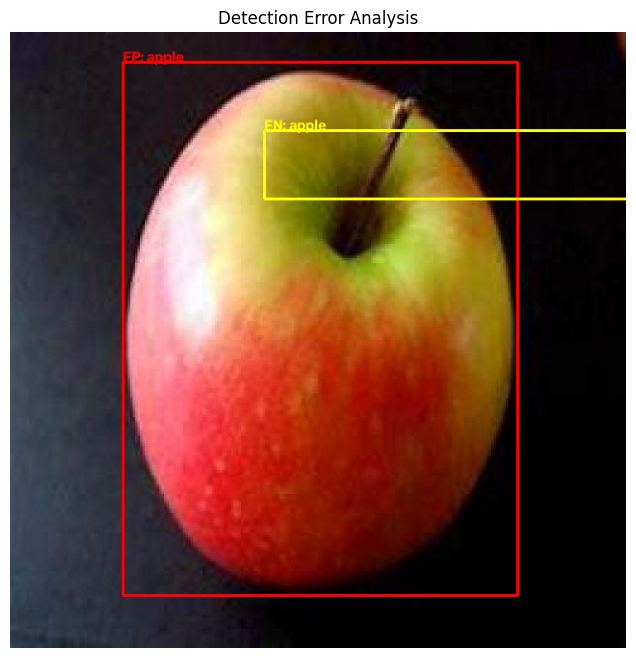

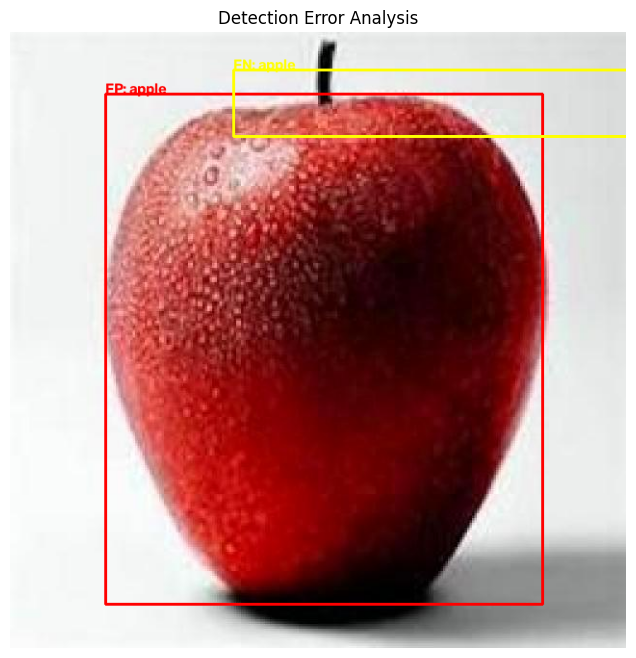

Images with errors displayed: 5


In [51]:
#Display images containing errors
error_count = 0

for analysis in analysis_results:

    if analysis["fp"] or analysis["fn"]:

        visualize_errors(analysis)

        error_count += 1

    if error_count == 5:
        break

print("Images with errors displayed:", error_count)

Analysis Report

The YOLOv8n model was fine-tuned on a Fruit and Vegetable Object Detection dataset and evaluated using 390 test images.

The model achieved a precision of **85.79%**, recall of **79.18%**, and mAP@0.5 of **84.70%**. At a stricter IoU threshold of 0.75, the mAP decreased to **73.07%**, indicating that bounding-box localization remains an area for improvement.

The per-class evaluation showed that Apple and Pepper achieved strong AP@0.5 scores of 91.90% and 92.73%, respectively. Tomato had the lowest recall at 59.07%, suggesting that the model missed a considerable number of tomato objects.

The error analysis identified:
- True Positives: 662
- False Positives: 323
- False Negatives: 232

Potential reasons for detection errors include object occlusion, similar visual appearances between classes, variations in object sizes, lighting conditions, and inaccurate bounding-box localization.

Overall, the model demonstrated good object detection performance, although improvements in recall, especially for Tomato, and bounding-box localization could further enhance its performance.